In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [30]:

from sklearn.linear_model import LogisticRegression


In [31]:
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('dataset/cleveland.csv', header=None)
df.columns = ['age', 'gender', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
              'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

In [32]:
df

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,2
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,3
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


In [33]:

df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

In [34]:
df

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,1
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,1
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


In [35]:
df['gender'] = df['gender'].map({0: 'female', 1: 'male'})

In [36]:
df

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,male,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,male,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,male,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,male,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,female,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,male,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,male,4,144,193,1,0,141,0,3.4,2,2.0,7.0,1
300,57,male,4,130,131,0,0,115,1,1.2,2,1.0,7.0,1
301,57,female,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


In [11]:
df['thal'] = pd.to_numeric(df['thal'], errors='coerce')

In [12]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,male,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,male,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,male,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,male,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,female,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,male,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,male,4,144,193,1,0,141,0,3.4,2,2.0,7.0,1
300,57,male,4,130,131,0,0,115,1,1.2,2,1.0,7.0,1
301,57,female,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


In [13]:
df['ca'] = pd.to_numeric(df['ca'], errors='coerce')

In [14]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,male,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,male,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,male,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,male,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,female,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,male,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,male,4,144,193,1,0,141,0,3.4,2,2.0,7.0,1
300,57,male,4,130,131,0,0,115,1,1.2,2,1.0,7.0,1
301,57,female,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


In [15]:
df['thal'].fillna(df['thal'].mean(), inplace=True)

In [16]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,male,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,male,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,male,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,male,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,female,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,male,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,male,4,144,193,1,0,141,0,3.4,2,2.0,7.0,1
300,57,male,4,130,131,0,0,115,1,1.2,2,1.0,7.0,1
301,57,female,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


In [17]:
df['ca'].fillna(df['ca'].mean(), inplace=True)

In [18]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,male,1,145,233,1,2,150,0,2.3,3,0.000000,6.0,0
1,67,male,4,160,286,0,2,108,1,1.5,2,3.000000,3.0,1
2,67,male,4,120,229,0,2,129,1,2.6,2,2.000000,7.0,1
3,37,male,3,130,250,0,0,187,0,3.5,3,0.000000,3.0,0
4,41,female,2,130,204,0,2,172,0,1.4,1,0.000000,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,male,1,110,264,0,0,132,0,1.2,2,0.000000,7.0,1
299,68,male,4,144,193,1,0,141,0,3.4,2,2.000000,7.0,1
300,57,male,4,130,131,0,0,115,1,1.2,2,1.000000,7.0,1
301,57,female,2,130,236,0,2,174,0,0.0,2,1.000000,3.0,1


In [37]:
df['gender'] = df['gender'].map({'female': 0, 'male': 1})

In [20]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.000000,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.000000,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.000000,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.000000,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.000000,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.000000,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.000000,7.0,1
300,57,1,4,130,131,0,0,115,1,1.2,2,1.000000,7.0,1
301,57,0,2,130,236,0,2,174,0,0.0,2,1.000000,3.0,1


In [21]:
#we will do model evaluation nowe

In [22]:
X = df.drop('target', axis=1).values
y = df['target'].values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [24]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [25]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

In [27]:
print("\n===== Logistic Regression =====")
print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Testing Accuracy : {accuracy_score(y_test, y_pred_test):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred_test))


===== Logistic Regression =====
Training Accuracy: 0.8388
Testing Accuracy : 0.8852
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61



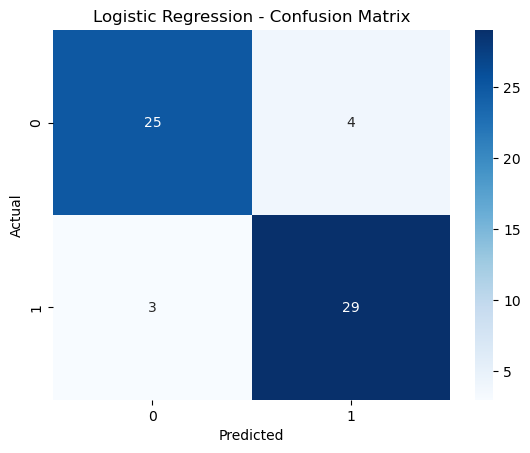

In [93]:
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# now we will convert the model and scaler into a pickle file to use it in a flask web app
import pickle
with open('model.pkl', 'wb') as model_file:
    pickle.dump(model, model_file)
 
with open('scaler.pkl', 'wb') as scaler_file:
    pickle.dump(scaler, scaler_file)   
